In [ ]:
# CELL 1 — Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries loaded successfully.")

# CELL 2 — Load Dataset

file_id = "1c5v2Enz5Xkur5aHx8DfRQUG-J56yUQKi"
url = f"https://drive.google.com/uc?id={file_id}"
df = pd.read_csv(url)

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Libraries loaded successfully.
Dataset loaded: 1460 rows, 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,Date,SaleType,SaleCondition,SalePrice,zip_code
0,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1/7/08,WD,Normal,118000,50010
1,142,20,RL,78.0,11645,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1/13/06,WD,Normal,260000,50012
2,293,50,RL,60.0,11409,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1/25/09,WD,Normal,131000,50013
3,151,20,RL,120.0,10356,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,1/29/07,WD,Normal,122000,50011
4,1036,20,RL,NaN,11500,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1/9/09,WD,Normal,84000,50012


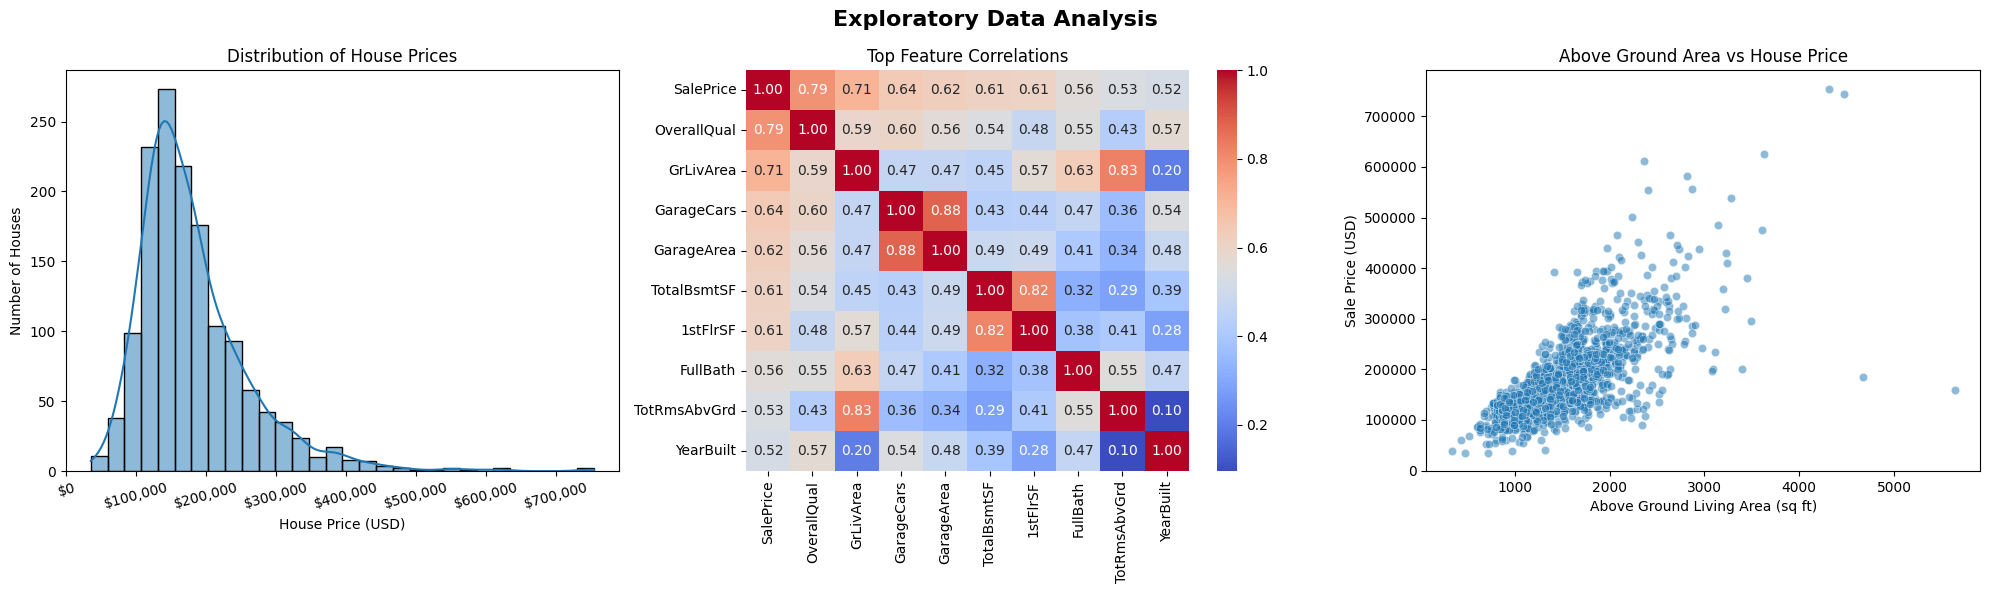

In [ ]:
# CELL — Visualizations (3 figures)

import matplotlib.ticker as mtick

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Exploratory Data Analysis", fontsize=16, fontweight='bold')

# --- Figure 1: Distribution of House Prices ---
sns.histplot(df["SalePrice"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of House Prices")
axes[0].set_xlabel("House Price (USD)")
axes[0].set_ylabel("Number of Houses")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${int(x):,}'))
axes[0].tick_params(axis='x', rotation=15)

# --- Figure 2: Top Feature Correlations Heatmap ---
top_corr = df.corr(numeric_only=True)["SalePrice"].abs().nlargest(10).index
sns.heatmap(df[top_corr].corr(), annot=True, cmap="coolwarm", ax=axes[1], fmt=".2f")
axes[1].set_title("Top Feature Correlations")

# --- Figure 3: GrLivArea vs SalePrice Scatter ---
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"], ax=axes[2], alpha=0.5)
axes[2].set_title("Above Ground Area vs House Price")
axes[2].set_xlabel("Above Ground Living Area (sq ft)")
axes[2].set_ylabel("Sale Price (USD)")

plt.tight_layout()
plt.show()



In [ ]:
# ──────────────────────────────────────────────
# CELL — Machine Learning Models & Evaluation
# ──────────────────────────────────────────────

TARGET = 'SalePrice'
X = df.drop(columns=['Id', 'Date', 'zip_code', TARGET], errors='ignore')
y = df[TARGET]

# Encode categorical columns
le = LabelEncoder()
for col in X.select_dtypes(include='object').columns:
    X[col] = le.fit_transform(X[col].astype(str))

X = X.fillna(0)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Scale features for Linear & Ridge
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# --- Model 1: Random Forest ---
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# --- Model 2: Linear Regression ---
lr_model = LinearRegression()
lr_model.fit(X_train_sc, y_train)
lr_preds = lr_model.predict(X_test_sc)

# --- Model 3: Ridge Regression ---
ridge_model = Ridge(alpha=10.0)
ridge_model.fit(X_train_sc, y_train)
ridge_preds = ridge_model.predict(X_test_sc)

# --- Evaluation Table ---
results = pd.DataFrame({
    'Model'    : ['Random Forest', 'Linear Regression', 'Ridge Regression'],
    'MAE ($)'  : [mean_absolute_error(y_test, rf_preds),
                  mean_absolute_error(y_test, lr_preds),
                  mean_absolute_error(y_test, ridge_preds)],
    'RMSE ($)' : [np.sqrt(mean_squared_error(y_test, rf_preds)),
                  np.sqrt(mean_squared_error(y_test, lr_preds)),
                  np.sqrt(mean_squared_error(y_test, ridge_preds))],
    'R² Score' : [r2_score(y_test, rf_preds),
                  r2_score(y_test, lr_preds),
                  r2_score(y_test, ridge_preds)],
})

results['MAE ($)']  = results['MAE ($)'].map('${:,.2f}'.format)
results['RMSE ($)'] = results['RMSE ($)'].map('${:,.2f}'.format)
results['R² Score'] = results['R² Score'].map('{:.4f}'.format)

results.style \
    .set_caption("Model Performance Comparison") \
    .set_properties(**{'text-align': 'center', 'font-size': '13px', 'padding': '8px 16px'}) \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding-bottom', '10px'), ('text-align', 'center')]},
        {'selector': 'th',
         'props': [('background-color', '#4a90a4'), ('color', 'white'),
                   ('font-size', '13px'), ('padding', '8px 16px'),
                   ('text-align', 'center')]},
        {'selector': 'tr:nth-child(even)',
         'props': [('background-color', '#f2f2f2')]},
        {'selector': 'tr:hover',
         'props': [('background-color', '#d6eaf8')]},
    ]) \
    .hide(axis='index')

Model,MAE ($),RMSE ($),R² Score
Random Forest,"$19,178.80","$32,009.16",0.8270
Linear Regression,"$21,260.53","$47,160.57",0.6244
Ridge Regression,"$21,203.57","$47,030.87",0.6265
